In [4]:
#Import all basic libraices
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## part 1 :Data Understanding and cleaning


In [5]:
#1.load the dataset
df=pd.read_csv("C:\\Users\\Asus\\Downloads\\amazon_sales_dataset.csv")
print(df)

       order_id  order_date  product_id product_category   price  \
0             1  2022-04-13        2637            Books  128.75   
1             2  2023-03-12        2300          Fashion  302.60   
2             3  2022-09-28        3670           Sports  495.80   
3             4  2022-04-17        2522            Books  371.95   
4             5  2022-03-13        1717           Beauty  201.68   
...         ...         ...         ...              ...     ...   
49995     49996  2022-09-03        1433           Beauty   26.99   
49996     49997  2022-07-03        1428           Beauty  294.23   
49997     49998  2023-02-17        4651      Electronics  352.11   
49998     49999  2022-09-30        4371           Beauty  307.54   
49999     50000  2023-06-29        2944   Home & Kitchen  253.44   

       discount_percent  quantity_sold customer_region payment_method  rating  \
0                    10              4   North America            UPI     3.5   
1                    

In [6]:
#2 display first 10 record
print(df.head(10))

   order_id  order_date  product_id product_category   price  \
0         1  2022-04-13        2637            Books  128.75   
1         2  2023-03-12        2300          Fashion  302.60   
2         3  2022-09-28        3670           Sports  495.80   
3         4  2022-04-17        2522            Books  371.95   
4         5  2022-03-13        1717           Beauty  201.68   
5         6  2023-12-02        1777           Sports  385.17   
6         7  2022-01-21        4068            Books   15.78   
7         8  2023-09-07        3537          Fashion  111.59   
8         9  2022-05-02        3262            Books  373.62   
9        10  2023-04-12        4174           Sports  134.81   

   discount_percent  quantity_sold customer_region    payment_method  rating  \
0                10              4   North America               UPI     3.5   
1                20              5            Asia       Credit Card     3.7   
2                20              2          Europe     

In [7]:
#3 display last 10 record
print(df.tail(10))

       order_id  order_date  product_id product_category   price  \
49990     49991  2023-04-08        2689           Beauty  265.49   
49991     49992  2023-06-26        1809      Electronics  489.56   
49992     49993  2022-12-30        4078          Fashion   33.20   
49993     49994  2022-09-04        3615           Sports  306.98   
49994     49995  2023-08-16        1942           Beauty   14.83   
49995     49996  2022-09-03        1433           Beauty   26.99   
49996     49997  2022-07-03        1428           Beauty  294.23   
49997     49998  2023-02-17        4651      Electronics  352.11   
49998     49999  2022-09-30        4371           Beauty  307.54   
49999     50000  2023-06-29        2944   Home & Kitchen  253.44   

       discount_percent  quantity_sold customer_region    payment_method  \
49990                20              1            Asia  Cash on Delivery   
49991                10              2          Europe       Credit Card   
49992                 0

In [8]:
#4 display 5 random records
print(df.sample(5))

       order_id  order_date  product_id product_category   price  \
16937     16938  2022-02-11        2523           Sports  167.91   
8033       8034  2023-10-27        3654   Home & Kitchen   65.94   
11921     11922  2023-01-16        2599           Sports   42.35   
5513       5514  2023-12-27        4766            Books  272.42   
17692     17693  2022-10-24        4138           Sports  381.67   

       discount_percent  quantity_sold customer_region    payment_method  \
16937                30              3     Middle East               UPI   
8033                  0              1     Middle East  Cash on Delivery   
11921                15              4     Middle East               UPI   
5513                  5              5            Asia        Debit Card   
17692                10              2   North America            Wallet   

       rating  review_count  discounted_price  total_revenue  
16937     3.7           214            117.54         352.62  
8033    

In [9]:
#5 chech data type of all columns
df.dtypes

order_id              int64
order_date              str
product_id            int64
product_category        str
price               float64
discount_percent      int64
quantity_sold         int64
customer_region         str
payment_method          str
rating              float64
review_count          int64
discounted_price    float64
total_revenue       float64
dtype: object

In [10]:
#6 find total rows and column
df.shape

(50000, 13)

In [11]:
#7 check for missing values
print(df.isnull().sum())

order_id            0
order_date          0
product_id          0
product_category    0
price               0
discount_percent    0
quantity_sold       0
customer_region     0
payment_method      0
rating              0
review_count        0
discounted_price    0
total_revenue       0
dtype: int64


In [12]:
#8 check for dulicate record
print(df.duplicated().sum())

0


## part 2: new column creatiom

In [13]:
#cover order_date and order_time  ---- making them proper --covert it to date time format
df['order_date']=pd.to_datetime(df['order_date'],dayfirst=True,format='mixed')

In [14]:
#1.extract year from order date
df['year']=df['order_date'].dt.year

In [15]:
#2 extract month form order date
df['month']=df['order_date'].dt.month

In [16]:
#3 extract month name form order date
df['month_name']=df['order_date'].dt.month_name()

In [17]:
#4 extract day form order date
df["day"]=df['order_date'].dt.day_name()

In [18]:
#5 create a colmun called revenue category
def revenue_category(revenue):
    if revenue>1000:
        return "high revenue"
    elif revenue>=500:
        return "medium revenue"
    else:
        return "low revenue"
df['revenue_category']=df['total_revenue'].apply(revenue_category)
df

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52,2022,4,April,Wednesday,low revenue
1,2,2023-12-03,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40,2023,12,December,Sunday,high revenue
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28,2022,9,September,Wednesday,medium revenue
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64,2022,4,April,Sunday,high revenue
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72,2022,3,March,Sunday,medium revenue
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,2022-03-09,1433,Beauty,26.99,0,5,Middle East,Credit Card,2.4,386,26.99,134.95,2022,3,March,Wednesday,low revenue
49996,49997,2022-03-07,1428,Beauty,294.23,10,5,Asia,Credit Card,3.1,8,264.81,1324.05,2022,3,March,Monday,high revenue
49997,49998,2023-02-17,4651,Electronics,352.11,30,4,Asia,Debit Card,3.1,104,246.48,985.92,2023,2,February,Friday,medium revenue
49998,49999,2022-09-30,4371,Beauty,307.54,5,1,Middle East,UPI,1.8,316,292.16,292.16,2022,9,September,Friday,low revenue


In [19]:
#6 create a acolumn called cutomer satifaction
def cutomer_satifaction(rating):
    if rating >=4.5:
        return "excellent"
    elif rating >=3:
        return "good"
    else:
        return "poor"
df['cutomer_satifaction']=df['rating'].apply(cutomer_satifaction)
df

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52,2022,4,April,Wednesday,low revenue,good
1,2,2023-12-03,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40,2023,12,December,Sunday,high revenue,good
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28,2022,9,September,Wednesday,medium revenue,good
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64,2022,4,April,Sunday,high revenue,excellent
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72,2022,3,March,Sunday,medium revenue,excellent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,2022-03-09,1433,Beauty,26.99,0,5,Middle East,Credit Card,2.4,386,26.99,134.95,2022,3,March,Wednesday,low revenue,poor
49996,49997,2022-03-07,1428,Beauty,294.23,10,5,Asia,Credit Card,3.1,8,264.81,1324.05,2022,3,March,Monday,high revenue,good
49997,49998,2023-02-17,4651,Electronics,352.11,30,4,Asia,Debit Card,3.1,104,246.48,985.92,2023,2,February,Friday,medium revenue,good
49998,49999,2022-09-30,4371,Beauty,307.54,5,1,Middle East,UPI,1.8,316,292.16,292.16,2022,9,September,Friday,low revenue,poor


## part 3:flitering analysis

In [20]:
#1 find all Electronics	 orders
df[df.product_category=="Electronics"]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
10,11,2022-03-08,4878,Electronics,67.43,20,4,Europe,Debit Card,4.3,426,53.94,215.76,2022,3,March,Tuesday,low revenue,good
12,13,2023-04-04,3222,Electronics,89.81,0,3,Europe,UPI,3.6,151,89.81,269.43,2023,4,April,Tuesday,low revenue,good
15,16,2022-10-04,3344,Electronics,419.66,0,3,Middle East,Credit Card,2.7,46,419.66,1258.98,2022,10,October,Tuesday,high revenue,poor
29,30,2022-01-22,4771,Electronics,239.79,15,5,North America,Credit Card,2.8,150,203.82,1019.10,2022,1,January,Saturday,high revenue,poor
33,34,2022-02-28,4053,Electronics,235.65,5,3,North America,Cash on Delivery,4.3,448,223.87,671.61,2022,2,February,Monday,medium revenue,good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49983,49984,2023-02-27,2593,Electronics,377.92,20,1,North America,Credit Card,1.1,162,302.34,302.34,2023,2,February,Monday,low revenue,poor
49984,49985,2023-04-14,2350,Electronics,125.94,10,3,Asia,Credit Card,1.1,256,113.35,340.05,2023,4,April,Friday,low revenue,poor
49986,49987,2022-07-11,4956,Electronics,338.40,5,4,Asia,Wallet,4.4,410,321.48,1285.92,2022,7,July,Monday,high revenue,good
49991,49992,2023-06-26,1809,Electronics,489.56,10,2,Europe,Credit Card,2.8,218,440.60,881.20,2023,6,June,Monday,medium revenue,poor


In [21]:
#2 print all order from asis
df[df.customer_region=="Asia"]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
1,2,2023-12-03,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40,2023,12,December,Sunday,high revenue,good
5,6,2023-02-12,1777,Sports,385.17,30,3,Asia,Wallet,3.8,489,269.62,808.86,2023,2,February,Sunday,medium revenue,good
6,7,2022-01-21,4068,Books,15.78,0,5,Asia,UPI,1.6,415,15.78,78.90,2022,1,January,Friday,low revenue,poor
8,9,2022-02-05,3262,Books,373.62,0,4,Asia,Wallet,2.8,497,373.62,1494.48,2022,2,February,Saturday,high revenue,poor
18,19,2023-10-24,1968,Home & Kitchen,262.36,10,1,Asia,Wallet,4.6,473,236.12,236.12,2023,10,October,Tuesday,low revenue,excellent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,49987,2022-07-11,4956,Electronics,338.40,5,4,Asia,Wallet,4.4,410,321.48,1285.92,2022,7,July,Monday,high revenue,good
49987,49988,2023-01-30,4670,Books,166.87,15,5,Asia,UPI,2.3,142,141.84,709.20,2023,1,January,Monday,medium revenue,poor
49990,49991,2023-08-04,2689,Beauty,265.49,20,1,Asia,Cash on Delivery,2.3,239,212.39,212.39,2023,8,August,Friday,low revenue,poor
49996,49997,2022-03-07,1428,Beauty,294.23,10,5,Asia,Credit Card,3.1,8,264.81,1324.05,2022,3,March,Monday,high revenue,good


In [22]:
#3. Find orders with RaƟng greater than 4.
df[df.rating>4]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28,2022,9,September,Wednesday,medium revenue,good
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64,2022,4,April,Sunday,high revenue,excellent
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72,2022,3,March,Sunday,medium revenue,excellent
10,11,2022-03-08,4878,Electronics,67.43,20,4,Europe,Debit Card,4.3,426,53.94,215.76,2022,3,March,Tuesday,low revenue,good
11,12,2022-11-27,3637,Books,150.19,0,1,North America,Cash on Delivery,4.4,279,150.19,150.19,2022,11,November,Sunday,low revenue,good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49975,49976,2022-12-26,2543,Electronics,408.82,10,1,Asia,UPI,4.4,71,367.94,367.94,2022,12,December,Monday,low revenue,good
49978,49979,2023-08-24,2642,Beauty,295.13,20,2,Middle East,Credit Card,4.1,27,236.10,472.20,2023,8,August,Thursday,low revenue,good
49979,49980,2023-05-30,2063,Books,375.41,10,4,Middle East,Wallet,4.4,268,337.87,1351.48,2023,5,May,Tuesday,high revenue,good
49986,49987,2022-07-11,4956,Electronics,338.40,5,4,Asia,Wallet,4.4,410,321.48,1285.92,2022,7,July,Monday,high revenue,good


In [23]:
#4. Find orders where Revenue exceeds 1000. 
df[df.total_revenue>1000]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
1,2,2023-12-03,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40,2023,12,December,Sunday,high revenue,good
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64,2022,4,April,Sunday,high revenue,excellent
8,9,2022-02-05,3262,Books,373.62,0,4,Asia,Wallet,2.8,497,373.62,1494.48,2022,2,February,Saturday,high revenue,poor
15,16,2022-10-04,3344,Electronics,419.66,0,3,Middle East,Credit Card,2.7,46,419.66,1258.98,2022,10,October,Tuesday,high revenue,poor
16,17,2023-10-26,3011,Sports,391.09,5,3,Middle East,Credit Card,3.7,51,371.54,1114.62,2023,10,October,Thursday,high revenue,good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49977,49978,2022-07-26,4991,Books,299.78,20,5,North America,Credit Card,1.3,273,239.82,1199.10,2022,7,July,Tuesday,high revenue,poor
49979,49980,2023-05-30,2063,Books,375.41,10,4,Middle East,Wallet,4.4,268,337.87,1351.48,2023,5,May,Tuesday,high revenue,good
49980,49981,2023-01-01,3664,Beauty,451.07,20,5,Europe,Debit Card,3.4,72,360.86,1804.30,2023,1,January,Sunday,high revenue,good
49986,49987,2022-07-11,4956,Electronics,338.40,5,4,Asia,Wallet,4.4,410,321.48,1285.92,2022,7,July,Monday,high revenue,good


In [24]:
#5. Find Fashion products sold in Asia. 
df[(df.product_category == "Fashion") & (df.customer_region == "Asia")]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
1,2,2023-12-03,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40,2023,12,December,Sunday,high revenue,good
51,52,2023-08-24,1567,Fashion,15.72,20,2,Asia,Debit Card,3.3,429,12.58,25.16,2023,8,August,Thursday,low revenue,good
58,59,2022-02-04,4041,Fashion,196.64,20,2,Asia,Credit Card,2.1,206,157.31,314.62,2022,2,February,Friday,low revenue,poor
64,65,2022-07-25,3903,Fashion,89.73,0,5,Asia,Cash on Delivery,4.3,399,89.73,448.65,2022,7,July,Monday,low revenue,good
83,84,2023-12-28,2023,Fashion,337.66,0,2,Asia,Cash on Delivery,2.6,316,337.66,675.32,2023,12,December,Thursday,medium revenue,poor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49818,49819,2023-08-10,1665,Fashion,468.31,30,3,Asia,Wallet,4.9,149,327.82,983.46,2023,8,August,Thursday,medium revenue,excellent
49819,49820,2022-05-12,4428,Fashion,193.58,0,5,Asia,Credit Card,1.4,147,193.58,967.90,2022,5,May,Thursday,medium revenue,poor
49921,49922,2022-11-18,4099,Fashion,383.48,10,3,Asia,Credit Card,2.5,456,345.13,1035.39,2022,11,November,Friday,high revenue,poor
49928,49929,2023-03-10,1989,Fashion,483.30,30,3,Asia,Cash on Delivery,1.2,35,338.31,1014.93,2023,3,March,Friday,high revenue,poor


In [25]:
#6. Find Electronics products with Rating above 4
df[(df.product_category=="Electronics")&(df.rating>4)]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
10,11,2022-03-08,4878,Electronics,67.43,20,4,Europe,Debit Card,4.3,426,53.94,215.76,2022,3,March,Tuesday,low revenue,good
33,34,2022-02-28,4053,Electronics,235.65,5,3,North America,Cash on Delivery,4.3,448,223.87,671.61,2022,2,February,Monday,medium revenue,good
35,36,2023-11-13,3197,Electronics,5.99,20,2,North America,UPI,4.5,89,4.79,9.58,2023,11,November,Monday,low revenue,excellent
67,68,2023-01-23,3558,Electronics,74.39,15,3,Middle East,Credit Card,5.0,384,63.23,189.69,2023,1,January,Monday,low revenue,excellent
75,76,2023-12-31,3952,Electronics,401.77,20,2,North America,UPI,4.6,38,321.42,642.84,2023,12,December,Sunday,medium revenue,excellent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49937,49938,2022-03-30,1862,Electronics,304.55,30,5,North America,Cash on Delivery,4.7,107,213.18,1065.90,2022,3,March,Wednesday,high revenue,excellent
49954,49955,2022-06-26,4204,Electronics,41.83,30,2,Asia,Credit Card,4.4,443,29.28,58.56,2022,6,June,Sunday,low revenue,good
49964,49965,2022-08-04,1911,Electronics,12.91,15,5,Middle East,Debit Card,4.4,281,10.97,54.85,2022,8,August,Thursday,low revenue,good
49975,49976,2022-12-26,2543,Electronics,408.82,10,1,Asia,UPI,4.4,71,367.94,367.94,2022,12,December,Monday,low revenue,good


In [26]:
#7. Find orders with Discount greater than 20%
df[df.discount_percent>20]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
5,6,2023-02-12,1777,Sports,385.17,30,3,Asia,Wallet,3.8,489,269.62,808.86,2023,2,February,Sunday,medium revenue,good
7,8,2023-07-09,3537,Fashion,111.59,30,4,Middle East,UPI,3.4,143,78.11,312.44,2023,7,July,Sunday,low revenue,good
17,18,2022-11-05,3222,Home & Kitchen,156.95,30,3,Middle East,Cash on Delivery,2.9,354,109.86,329.58,2022,11,November,Saturday,low revenue,poor
19,20,2022-05-11,3390,Fashion,428.24,30,3,Middle East,Wallet,1.2,331,299.77,899.31,2022,5,May,Wednesday,medium revenue,poor
38,39,2022-09-07,4014,Beauty,110.54,30,4,Europe,Credit Card,3.5,4,77.38,309.52,2022,9,September,Wednesday,low revenue,good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49960,49961,2022-01-27,4777,Fashion,147.08,30,2,Europe,Debit Card,3.7,160,102.96,205.92,2022,1,January,Thursday,low revenue,good
49965,49966,2022-11-22,2579,Fashion,352.45,30,4,North America,Debit Card,4.6,428,246.71,986.84,2022,11,November,Tuesday,medium revenue,excellent
49968,49969,2023-09-22,1158,Beauty,380.67,30,2,North America,Wallet,3.9,89,266.47,532.94,2023,9,September,Friday,medium revenue,good
49997,49998,2023-02-17,4651,Electronics,352.11,30,4,Asia,Debit Card,3.1,104,246.48,985.92,2023,2,February,Friday,medium revenue,good


In [27]:
#8. Find orders paid using UPI and having Rating above 4. 
df[(df.payment_method=='UPI') & (df.rating)]

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue,year,month,month_name,day,revenue_category,cutomer_satifaction
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52,2022,4,April,Wednesday,low revenue,good
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28,2022,9,September,Wednesday,medium revenue,good
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64,2022,4,April,Sunday,high revenue,excellent
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72,2022,3,March,Sunday,medium revenue,excellent
6,7,2022-01-21,4068,Books,15.78,0,5,Asia,UPI,1.6,415,15.78,78.90,2022,1,January,Friday,low revenue,poor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49969,49970,2023-10-09,4993,Electronics,414.64,0,5,Europe,UPI,3.0,267,414.64,2073.20,2023,10,October,Monday,high revenue,good
49974,49975,2022-12-30,1385,Books,356.12,5,1,North America,UPI,1.1,221,338.31,338.31,2022,12,December,Friday,low revenue,poor
49975,49976,2022-12-26,2543,Electronics,408.82,10,1,Asia,UPI,4.4,71,367.94,367.94,2022,12,December,Monday,low revenue,good
49987,49988,2023-01-30,4670,Books,166.87,15,5,Asia,UPI,2.3,142,141.84,709.20,2023,1,January,Monday,medium revenue,poor


## Part 4: Business KPIs

In [28]:
#1. Calculate Total Revenue
t_revenue=df['total_revenue'].sum()
print("Total revenue:",t_revenue)

Total revenue: 32866573.740000002


In [29]:
#2. Calculate Total QuanƟty Sold. 
t_qty=df['quantity_sold'].sum()
print("Total quantity sold:",t_qty)

Total quantity sold: 149970


In [30]:
#3. Calculate Total Orders. 
t_order=df['order_id'].nunique()
print("Total order:",t_order)

Total order: 50000


In [31]:
#4. Calculate Average Revenue per Order. 
avg_order=df['quantity_sold'].sum()/df['order_id'].nunique()
print("average pizza per order:",avg_order)
print("average pizza per order:",round(avg_order,2))

average pizza per order: 2.9994
average pizza per order: 3.0


In [32]:
#5. Calculate Average Rating.
avg_rating=df["rating"].mean()
print("Average Rating",round(avg_rating,2))

Average Rating 3.0


In [33]:
#6. Calculate Average Discount Given
avg_dis=df["discount_percent"].mean()
print("Average Discount",round(avg_dis,2))

Average Discount 13.34


In [34]:
#7. Find Total Number of Products Sold
total_products_sold=df['quantity_sold'].sum()
print("Total Number of Products Sold:",total_products_sold)

Total Number of Products Sold: 149970


In [35]:
#8. Find Total Revenue Lost Due to Discounts. 
lost=df["discounted_price"].sum()
print("Total Revenue Lost Due to Discounts:",lost)

Total Revenue Lost Due to Discounts: 10944328.29


## Part 5: Category Analysis 


In [36]:
#1. Total Revenue by Product Category. 
a=df.groupby('product_category')['total_revenue'].sum()
print(a)

product_category
Beauty            5550624.97
Books             5484863.03
Electronics       5470594.03
Fashion           5480123.34
Home & Kitchen    5473132.55
Sports            5407235.82
Name: total_revenue, dtype: float64


In [37]:
#2. Total Quantity Sold by Product Category. 
b=df.groupby('product_category')['quantity_sold'].sum()
print(b)

product_category
Beauty            25422
Books             25065
Electronics       24898
Fashion           25089
Home & Kitchen    24743
Sports            24753
Name: quantity_sold, dtype: int64


In [38]:
#3. Average Rating by Product Category
c=df.groupby('product_category')['rating'].mean()
print(c)

product_category
Beauty            2.985186
Books             3.020259
Electronics       2.991298
Fashion           2.987782
Home & Kitchen    2.996706
Sports            2.996891
Name: rating, dtype: float64


In [39]:
#4. Average Discount by Product Category. 
d=df.groupby('product_category')['discount_percent'].mean()
print(d)

product_category
Beauty            13.371530
Books             13.337336
Electronics       13.258413
Fashion           13.358637
Home & Kitchen    13.311334
Sports            13.406534
Name: discount_percent, dtype: float64


In [40]:
#5. Highest Revenue Generating Category. 
e=df.groupby("product_category")["total_revenue"].sum().sort_values(ascending=False).head(1)
print(e)

product_category
Beauty    5550624.97
Name: total_revenue, dtype: float64


In [41]:
#6.Lowest Revenue GeneraƟng Category. 
f=df.groupby("product_category")["total_revenue"].sum().sort_values(ascending=False).tail(1)
print(f)

product_category
Sports    5407235.82
Name: total_revenue, dtype: float64


In [42]:
#7. Highest Selling Category
g=df.groupby("product_category")["quantity_sold"].sum().sort_values(ascending=False).head(1)

print(g)


product_category
Beauty    25422
Name: quantity_sold, dtype: int64


In [43]:
#8. Lowest Selling Category. 
h=df.groupby("product_category")["quantity_sold"].sum().sort_values(ascending=False).tail(1)
print(h)


product_category
Home & Kitchen    24743
Name: quantity_sold, dtype: int64


## Part 6: Region Analysis

In [44]:
# 1. Total Revenue by Region
i=df.groupby("customer_region")["total_revenue"].sum()
print(i)

customer_region
Asia             8175199.83
Europe           8112311.57
Middle East      8301844.50
North America    8277217.84
Name: total_revenue, dtype: float64


In [45]:
# 2. Total Quantity Sold by Region
j=df.groupby("customer_region")["quantity_sold"].sum()
print(j)

customer_region
Asia             37440
Europe           37302
Middle East      37694
North America    37534
Name: quantity_sold, dtype: int64


In [46]:

# 4. Highest Revenue Region
k=df.groupby("customer_region")["total_revenue"].sum().sort_values(ascending=False).head(1)
print(k)

customer_region
Middle East    8301844.5
Name: total_revenue, dtype: float64


In [47]:
# 5. Lowest Revenue Region
l=df.groupby("customer_region")["total_revenue"].sum().sort_values(ascending=True).head(1)
print(l)

customer_region
Europe    8112311.57
Name: total_revenue, dtype: float64


In [48]:
# 6. Region with Maximum Orders
m=df.groupby("customer_region")["order_id"].count().sort_values(ascending=False).head(1)
print(m)

customer_region
Asia    12526
Name: order_id, dtype: int64


In [49]:

# 7. Region with Minimum Orders
n=df.groupby("customer_region")["order_id"].count().sort_values(ascending=True).head(1)
print(n)

customer_region
Europe    12452
Name: order_id, dtype: int64


## Part 7: Payment Method Analysis

In [50]:
# 1. Total Revenue by Payment Method
o=df.groupby("payment_method")["total_revenue"].sum()
print(o)


payment_method
Cash on Delivery    6546386.94
Credit Card         6540087.16
Debit Card          6522019.73
UPI                 6579441.44
Wallet              6678638.47
Name: total_revenue, dtype: float64


In [51]:

# 2. Total Orders by Payment Method
p=df.groupby("payment_method")["order_id"].count()
print(p)

payment_method
Cash on Delivery     9927
Credit Card          9908
Debit Card           9981
UPI                 10078
Wallet              10106
Name: order_id, dtype: int64


In [52]:

# 3. Average Rating by Payment Method
q=df.groupby("payment_method")["rating"].mean()
print(q)

payment_method
Cash on Delivery    3.010305
Credit Card         2.994732
Debit Card          2.989420
UPI                 2.998174
Wallet              2.989086
Name: rating, dtype: float64


In [53]:
# 4. Most Preferred Payment Method
r=df.groupby("payment_method")["order_id"].count().sort_values(ascending=False).head(1)
print(r)

payment_method
Wallet    10106
Name: order_id, dtype: int64


In [54]:
# 5. Least Preferred Payment Method
s=df.groupby("payment_method")["order_id"].count().sort_values(ascending=True).head(1)
print(s)

payment_method
Credit Card    9908
Name: order_id, dtype: int64


## Part 8: Discount Analysis 


In [55]:
# 1. Revenue Generated by Each Discount Level
t=df.groupby("discount_percent")["total_revenue"].sum()
print(t)

discount_percent
0     6154055.31
5     6182826.90
10    5732411.47
15    5322103.91
20    5128525.23
30    4346650.92
Name: total_revenue, dtype: float64


In [56]:
# 2. Average Rating by Discount Level
u=df.groupby("discount_percent")["rating"].mean()
print(u)

discount_percent
0     3.007814
5     2.982331
10    2.982099
15    2.997521
20    2.999125
30    3.009383
Name: rating, dtype: float64


In [57]:
# 3. Which Discount Percentage Generated Maximum Revenue?
v=df.groupby("discount_percent")["total_revenue"].sum().sort_values(ascending=False).head(1)
print(v)

discount_percent
5    6182826.9
Name: total_revenue, dtype: float64


In [58]:

# 4. Which Discount Percentage Received Highest Ratings?
w=df.groupby("discount_percent")["rating"].mean().sort_values(ascending=False).head(1)
print(w)

discount_percent
30    3.009383
Name: rating, dtype: float64


## Part 9: Customer Review Analysis

In [59]:
# 1. Average Rating by Category
x=df.groupby("product_category")["rating"].mean()
print(x)

product_category
Beauty            2.985186
Books             3.020259
Electronics       2.991298
Fashion           2.987782
Home & Kitchen    2.996706
Sports            2.996891
Name: rating, dtype: float64


In [60]:
# 2. Average Rating by Region
y=df.groupby("customer_region")["rating"].mean()
print(y)

customer_region
Asia             2.995721
Europe           2.973651
Middle East      3.015434
North America    3.000360
Name: rating, dtype: float64


In [61]:
# 3. Highest Rated Category
z=df.groupby("product_category")["rating"].mean().sort_values(ascending=False).head(1)
print(z)

product_category
Books    3.020259
Name: rating, dtype: float64


In [62]:
# 4. Lowest Rated Category
a=df.groupby("product_category")["rating"].mean().sort_values(ascending=True).head(1)
print(a)

product_category
Beauty    2.985186
Name: rating, dtype: float64


In [63]:
# 5. Categories with More Than 100 Average Reviews
b=df.groupby("product_category")["rating"].count().loc[lambda x: x > 100]
print(b)

product_category
Beauty            8465
Books             8327
Electronics       8320
Fashion           8365
Home & Kitchen    8258
Sports            8265
Name: rating, dtype: int64


## Part 10: Date Analysis 


In [64]:
# 1. Total Revenue by Year
c=df.groupby("year")["total_revenue"].sum()
print(c)


year
2022    16389404.56
2023    16477169.18
Name: total_revenue, dtype: float64


In [65]:
# 2. Total Orders by Year
d=df.groupby("year")["order_id"].count()
print(d)


year
2022    24926
2023    25074
Name: order_id, dtype: int64


In [66]:
# 3. Total Revenue by Month
e=df.groupby("month")["total_revenue"].sum()
print(e)


month
1     2845570.89
2     2536197.72
3     2783390.52
4     2726271.18
5     2745552.42
6     2621544.54
7     2780520.32
8     2871940.13
9     2705251.76
10    2834001.88
11    2715227.48
12    2701104.90
Name: total_revenue, dtype: float64


In [67]:
# 4. Total Orders by Month
f=df.groupby("month")["order_id"].count()
print(f)

month
1     4334
2     3798
3     4337
4     4139
5     4191
6     4042
7     4267
8     4299
9     4097
10    4298
11    4091
12    4107
Name: order_id, dtype: int64


In [68]:
# 5. Month with Highest Revenue
g=df.groupby("month")["total_revenue"].sum().sort_values(ascending=False).head(1)
print(g)

month
8    2871940.13
Name: total_revenue, dtype: float64


In [69]:
# 6. Month with Lowest Revenue
h=df.groupby("month")["total_revenue"].sum().sort_values(ascending=True).head(1)
print(h)

month
2    2536197.72
Name: total_revenue, dtype: float64


In [70]:
# 7. Month with Highest Sales
i=df.groupby("month")["quantity_sold"].sum().sort_values(ascending=False).head(1)
print(i)

month
1    13101
Name: quantity_sold, dtype: int64


In [71]:
# 8. Month with Lowest Sales
j=df.groupby("month")["quantity_sold"].sum().sort_values(ascending=True).head(1)
print(j)

month
2    11337
Name: quantity_sold, dtype: int64


In [72]:
# 9. Day-wise Revenue Analysis
k=df.groupby("day")["total_revenue"].sum()
print(k)


day
Friday       4781746.79
Monday       4607393.61
Saturday     4705758.72
Sunday       4801441.94
Thursday     4670187.12
Tuesday      4622785.14
Wednesday    4677260.42
Name: total_revenue, dtype: float64


In [73]:
# 10. Day-wise Sales Analysis
l=df.groupby("day")["quantity_sold"].sum()
print(l)

day
Friday       21890
Monday       21105
Saturday     21325
Sunday       21830
Thursday     21406
Tuesday      21039
Wednesday    21375
Name: quantity_sold, dtype: int64


## Part 11: Top & Bo om Analysis 

In [74]:
#1. Top 10 Products by Revenue.
m=df.groupby('product_id')['total_revenue'].sum().sort_values(ascending=False).head(10)
print(m)

product_id
1931    18885.83
1087    18531.52
1328    18306.73
3537    18071.02
2837    17855.07
1266    17819.13
4386    17806.08
4264    17803.51
3700    17619.14
3377    17201.38
Name: total_revenue, dtype: float64


In [75]:
#2. Bottom 10 Products by Revenue.
n=df.groupby('product_id')['total_revenue'].sum().sort_values(ascending=True).head(10)
print(n)

product_id
3694     558.54
3054    1050.78
4514    1063.20
4028    1088.07
3715    1162.27
1425    1297.63
2297    1314.51
4893    1379.32
4702    1425.52
3826    1621.38
Name: total_revenue, dtype: float64


In [76]:
#3. Top 10 Products by Quantity Sold. 
o=df.groupby('product_id')['quantity_sold'].sum().sort_values(ascending=False).head(10)
print(o)

product_id
1087    81
1580    80
3537    79
4217    79
1617    78
2048    78
1386    77
2785    77
4204    77
3700    75
Name: quantity_sold, dtype: int64


In [77]:
#4. Bottom 10 Products by Quantity Sold.  
p=df.groupby('product_id')['quantity_sold'].sum().sort_values(ascending=True).head(10)
print(p)

product_id
3694     3
4033     6
4957     8
3606     8
1267     9
4028     9
4536     9
4514    10
2213    10
2199    11
Name: quantity_sold, dtype: int64


In [78]:
#5. Top 5 Categories by Revenue. 
q=df.groupby('product_category')['total_revenue'].sum().sort_values(ascending=False).head(5)
print(q)

product_category
Beauty            5550624.97
Books             5484863.03
Fashion           5480123.34
Home & Kitchen    5473132.55
Electronics       5470594.03
Name: total_revenue, dtype: float64


In [79]:
#6. Bottom 5 Categories by Revenue. 
r=df.groupby('product_category')['total_revenue'].sum().sort_values(ascending=True).head(5)
print(r)

product_category
Sports            5407235.82
Electronics       5470594.03
Home & Kitchen    5473132.55
Fashion           5480123.34
Books             5484863.03
Name: total_revenue, dtype: float64


In [80]:
#7. Top 5 Regions by Revenue.  
s=df.groupby('customer_region')['total_revenue'].sum().sort_values(ascending=False).head(5)
print(s)

customer_region
Middle East      8301844.50
North America    8277217.84
Asia             8175199.83
Europe           8112311.57
Name: total_revenue, dtype: float64


In [81]:
#8. bottom 5 Regions by Revenue.  
t=df.groupby('customer_region')['total_revenue'].sum().sort_values(ascending=True).head(5)
print(t)

customer_region
Europe           8112311.57
Asia             8175199.83
North America    8277217.84
Middle East      8301844.50
Name: total_revenue, dtype: float64


## Part 12: Visualizations 

## Bar Charts 

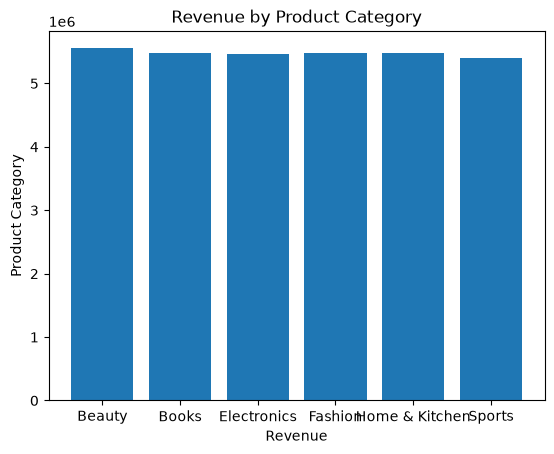

In [82]:
#1. Revenue by Product Category.  
m = df.groupby('product_category')['total_revenue'].sum()

x = m.index
y = m.values

plt.bar(x, y)

plt.title("Revenue by Product Category")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.show()


customer_region
Asia             8175199.83
Europe           8112311.57
Middle East      8301844.50
North America    8277217.84
Name: total_revenue, dtype: float64


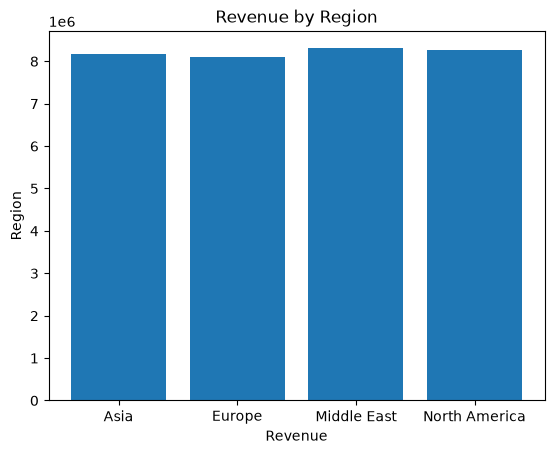

In [83]:
#2. Revenue by Region. 
m = df.groupby('customer_region')['total_revenue'].sum()
print(m)
x = m.index
y = m.values
plt.bar(x, y)
plt.title("Revenue by Region")
plt.xlabel("Revenue")
plt.ylabel("Region")
plt.show()

payment_method
Cash on Delivery    6546386.94
Credit Card         6540087.16
Debit Card          6522019.73
UPI                 6579441.44
Wallet              6678638.47
Name: total_revenue, dtype: float64


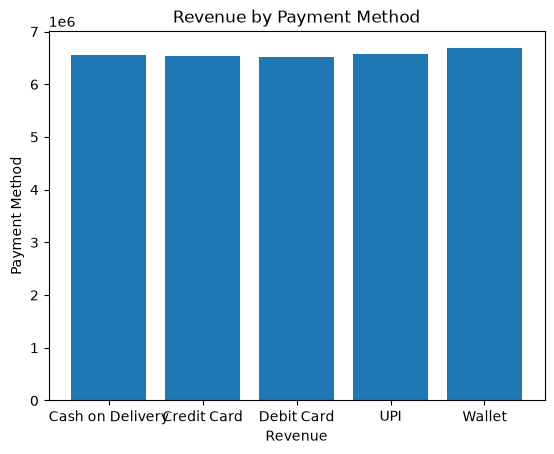

In [84]:
#3. Revenue by Payment Method.
m = df.groupby('payment_method')['total_revenue'].sum()
print(m)
x = m.index
y = m.values
plt.bar(x, y)
plt.title("Revenue by Payment Method")
plt.xlabel("Revenue")
plt.ylabel("Payment Method")
plt.show()

## Horizontal Bar Charts 

product_category
Beauty            5550624.97
Books             5484863.03
Fashion           5480123.34
Home & Kitchen    5473132.55
Electronics       5470594.03
Sports            5407235.82
Name: total_revenue, dtype: float64


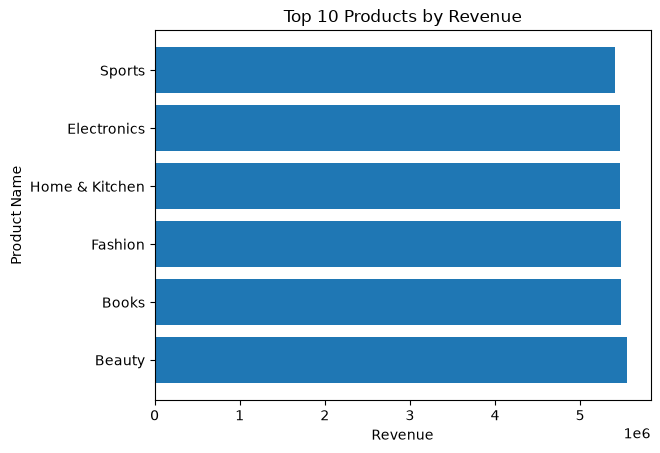

In [85]:
#1. Top 10 Products by Revenue.  
m = df.groupby('product_category')['total_revenue'].sum().sort_values(ascending=False).head(10)
print(m)
x = m.index
y = m.values
plt.barh(x, y)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Name")
plt.show() 

product_category
Beauty            25422
Fashion           25089
Books             25065
Electronics       24898
Sports            24753
Home & Kitchen    24743
Name: quantity_sold, dtype: int64


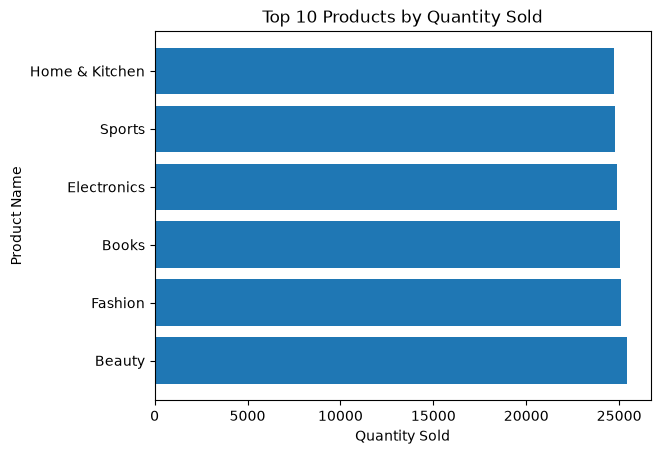

In [86]:
# 2. Top 10 Products by Quan ty Sold.
m = df.groupby('product_category')['quantity_sold'].sum().sort_values(ascending=False).head(10)
print(m)
x = m.index
y = m.values
plt.barh(x, y)
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Name")
plt.show()

## Pie Charts 


product_category
Beauty            5550624.97
Books             5484863.03
Electronics       5470594.03
Fashion           5480123.34
Home & Kitchen    5473132.55
Sports            5407235.82
Name: total_revenue, dtype: float64


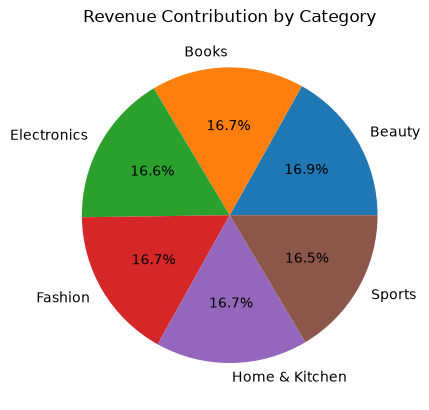

In [87]:
# 1. Revenue Contribution by Category. 
m = df.groupby('product_category')['total_revenue'].sum()
print(m)
plt.pie(m.values, labels=m.index, autopct='%1.1f%%')
plt.title("Revenue Contribution by Category")
plt.show()


payment_method
Cash on Delivery    249110491
Credit Card         247679108
Debit Card          249724186
UPI                 249964292
Wallet              253546923
Name: order_id, dtype: int64


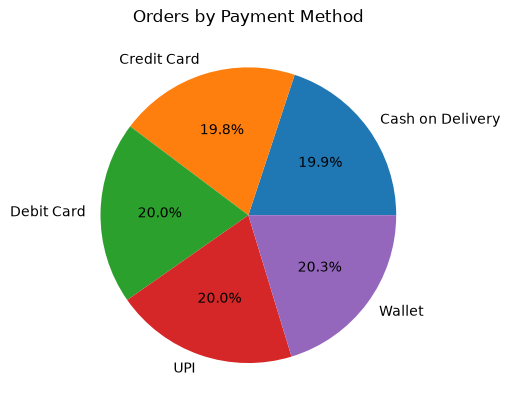

In [88]:
# 2. Orders by Payment Method
m = df.groupby('payment_method')['order_id'].sum()
print(m)
plt.pie(m.values, labels=m.index, autopct='%1.1f%%')
plt.title("Orders by Payment Method")
plt.show()

## Histograms 


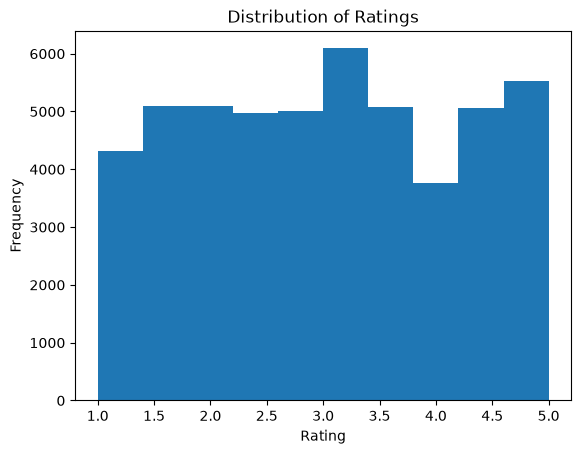

In [89]:
# 1. Distribution of Ratings.  
plt.hist(df['rating'])
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

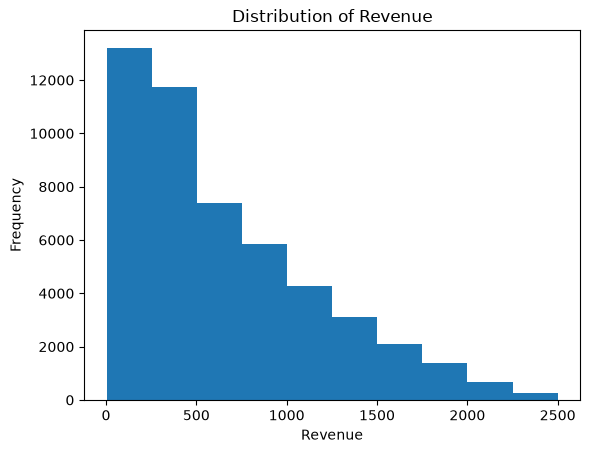

In [90]:
# 2. Distribution of Revenues
plt.hist(df['total_revenue'])
plt.title("Distribution of Revenue")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

## Scatter Plots 

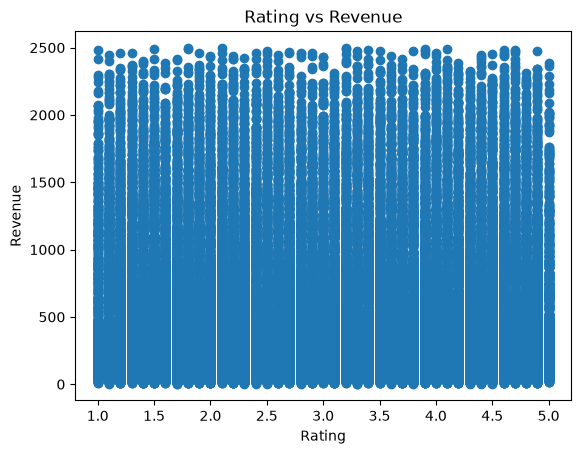

In [91]:
#1. Rating vs Revenue
x = df['rating']
y = df['total_revenue']
plt.scatter(x, y)
plt.title("Rating vs Revenue")
plt.xlabel("Rating")
plt.ylabel("Revenue")
plt.show()

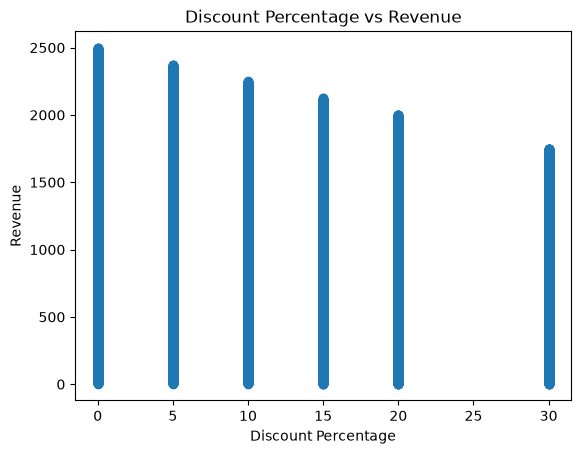

In [92]:
# 2. Discount Percentage vs Revenue. 
x = df['discount_percent']
y = df['total_revenue']
plt.scatter(x, y)
plt.title("Discount Percentage vs Revenue")
plt.xlabel("Discount Percentage")
plt.ylabel("Revenue")
plt.show()

## Line Charts 

month
1     2845570.89
2     2536197.72
3     2783390.52
4     2726271.18
5     2745552.42
6     2621544.54
7     2780520.32
8     2871940.13
9     2705251.76
10    2834001.88
11    2715227.48
12    2701104.90
Name: total_revenue, dtype: float64


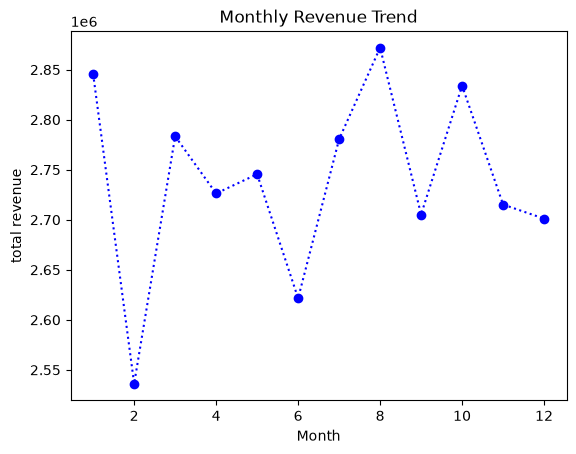

In [93]:
# 1. Monthly Revenue Trend.
a = df.groupby('month')['total_revenue'].sum()
print(a)
x = a.index
y = a.values
plt.plot(x,y,'bo:')
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("total revenue")
plt.show()

month
1     13101
2     11337
3     12945
4     12456
5     12493
6     12110
7     12690
8     12828
9     12322
10    13045
11    12391
12    12252
Name: quantity_sold, dtype: int64


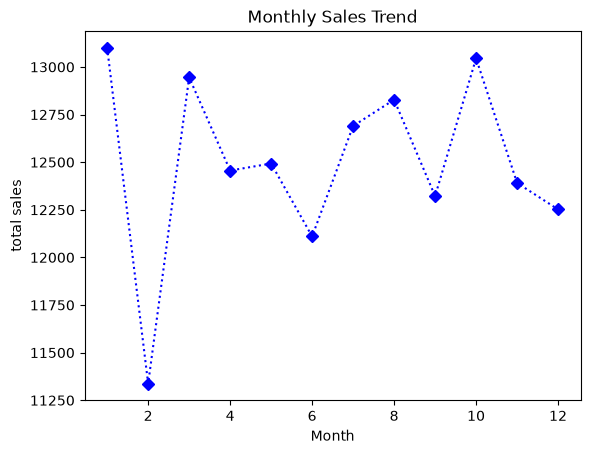

In [94]:
#2. Monthly Sales Trend. 
a = df.groupby('month')['quantity_sold'].sum()
print(a)
x = a.index
y = a.values
plt.plot(x,y,'bD:')
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("total sales")
plt.show()


Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int32', name='month')


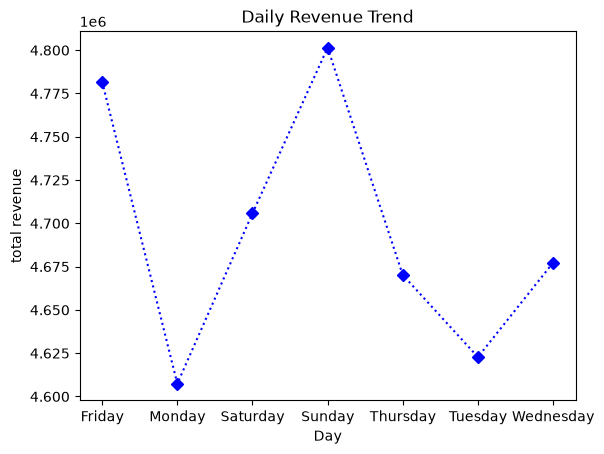

In [95]:
#3. Daily Revenue Trend 
a = df.groupby('day')['total_revenue'].sum()
print(x)
x = a.index
y = a.values
plt.plot(x,y,'bD:')
plt.title("Daily Revenue Trend")
plt.xlabel("Day")
plt.ylabel("total revenue")
plt.show()

Index(['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday',
       'Wednesday'],
      dtype='str', name='day')


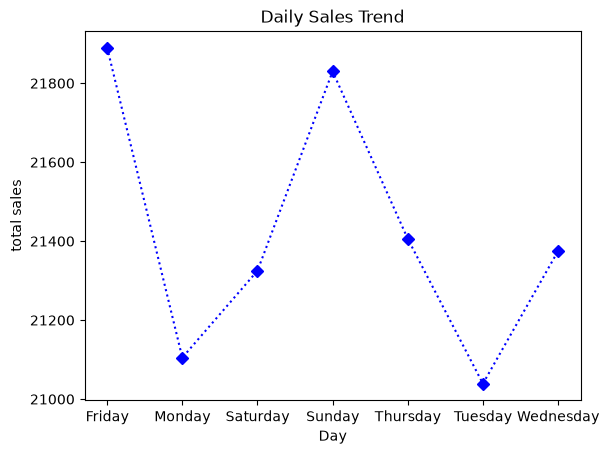

In [96]:
#4. Daily Sales Trend 
a = df.groupby('day')['quantity_sold'].sum()
print(x)
x = a.index
y = a.values
plt.plot(x,y,'bD:')
plt.title("Daily Sales Trend")
plt.xlabel("Day")
plt.ylabel("total sales")
plt.show()

In [97]:
df.to_csv("amamzon_sale_clean.csv")